# Prophet Model

This ipynb file contains the developement, tuning and  Prophet model exploration. The dataset used in this stage is the one which was cleaned, explored and processed on the EDA part.


# Experiment 1:
Build and fine tune a Prophet model using the **Dublin weather dataset**, **neither differencing nor log transformation techniques has been applied** for this experiment.

### Import Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Prophet model
from prophet import Prophet

# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#random seachcv
from sklearn.model_selection import RandomizedSearchCV
import random

## Load Dataset

In [2]:
df=pd.read_csv('Datasets/dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Prophet model's data processing

Prophet models require a column called 'ds' for time, and 'y' for the target feature


In [3]:
# Rename columns as Prophet expects
df = df.rename(columns={'datetime': 'ds', 'solarradiation': 'y'})


Adittionally, the exogenous variables have to be defined into a list

In [6]:
df.columns

Index(['ds', 'tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'y'],
      dtype='object')

In [4]:
# Define Exogenous data or regressors
X =['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility']

In [7]:
df.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Split data into 80/20

Creating the features for training and testing prophet model

In [5]:
# Separate historical and future data
train = df[df['ds'] < '2022-12-31']
test = df[df['ds'] >= '2022-12-31'].copy()

In [9]:
train.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


In [11]:
test.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
2921,2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,13.0
2922,2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,10.6
2923,2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,22.2
2924,2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,15.8
2925,2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,18.2


## Building the Model

In [6]:
# Initialize Prophet model
model = Prophet(growth='logistic',
    yearly_seasonality=True,
    weekly_seasonality=True,
    changepoint_prior_scale=0.1,       # allow more trend flexibility
    seasonality_prior_scale=20.0, )     # allow stronger seasonal variation)

In [7]:
# add regressors (exogenous variables)

for x in X:
    model.add_regressor(x, standardize='auto')

In [8]:
# checking for exogenous variables that the model expects
print("Model expects:", list(model.extra_regressors.keys()))


Model expects: ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility']


### Fit the model

In [9]:
# Fit the model using train data
model.fit(train)

ValueError: Capacities must be supplied for logistic growth in column "cap"

### Predict values

In [110]:
predicted=model.predict(test)

Prophet model shows the predicted values in 'yhat' feature

In [18]:
predicted.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,cloudcover,...,windspeed,windspeed_lower,windspeed_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2022-12-31,102.147115,-53.298805,29.930527,102.147115,102.147115,-111.580915,-111.580915,-111.580915,-29.192933,...,-4.845516,-4.845516,-4.845516,-58.797589,-58.797589,-58.797589,0.0,0.0,0.0,-9.433801
1,2023-01-01,102.140995,-54.112172,36.344563,102.140995,102.140995,-110.376930,-110.376930,-110.376930,-13.954215,...,-3.452744,-3.452744,-3.452744,-58.626954,-58.626954,-58.626954,0.0,0.0,0.0,-8.235935
2,2023-01-02,102.134875,-3.439031,82.897986,102.134875,102.134875,-63.191717,-63.191717,-63.191717,24.319774,...,-1.108812,-1.108812,-1.108812,-58.429050,-58.429050,-58.429050,0.0,0.0,0.0,38.943158
3,2023-01-03,102.128756,-45.223052,36.766733,102.128756,102.128756,-106.535560,-106.535560,-106.535560,-25.767175,...,2.695832,2.695832,2.695832,-58.205695,-58.205695,-58.205695,0.0,0.0,0.0,-4.406804
4,2023-01-04,102.122636,-14.411433,71.656385,102.122636,102.122636,-75.888979,-75.888979,-75.888979,-14.072345,...,2.390102,2.390102,2.390102,-57.958295,-57.958295,-57.958295,0.0,0.0,0.0,26.233657


### Accuracy

In order to make a comparison of the models' performance, a systematic analysis of statistical evaluation metrics, including the R² score, Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE) is cumputed.

In [111]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['y'], predicted['yhat']))
mae = mean_absolute_error(test['y'], predicted['yhat'])
r2 = r2_score(test['y'], predicted['yhat'])
mape = mean_absolute_percentage_error(test['y'], predicted['yhat'])

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape:4f}")

RMSE: 30.3407
MAE: 23.3179
R² Score: 0.8347
MAPE: 0.503904


In [112]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [113]:
print("SMAPE:", smape(test['y'], predicted['yhat']))

SMAPE: 45.275384818335624


## Plot Actual Test data vs Forecasted Test data

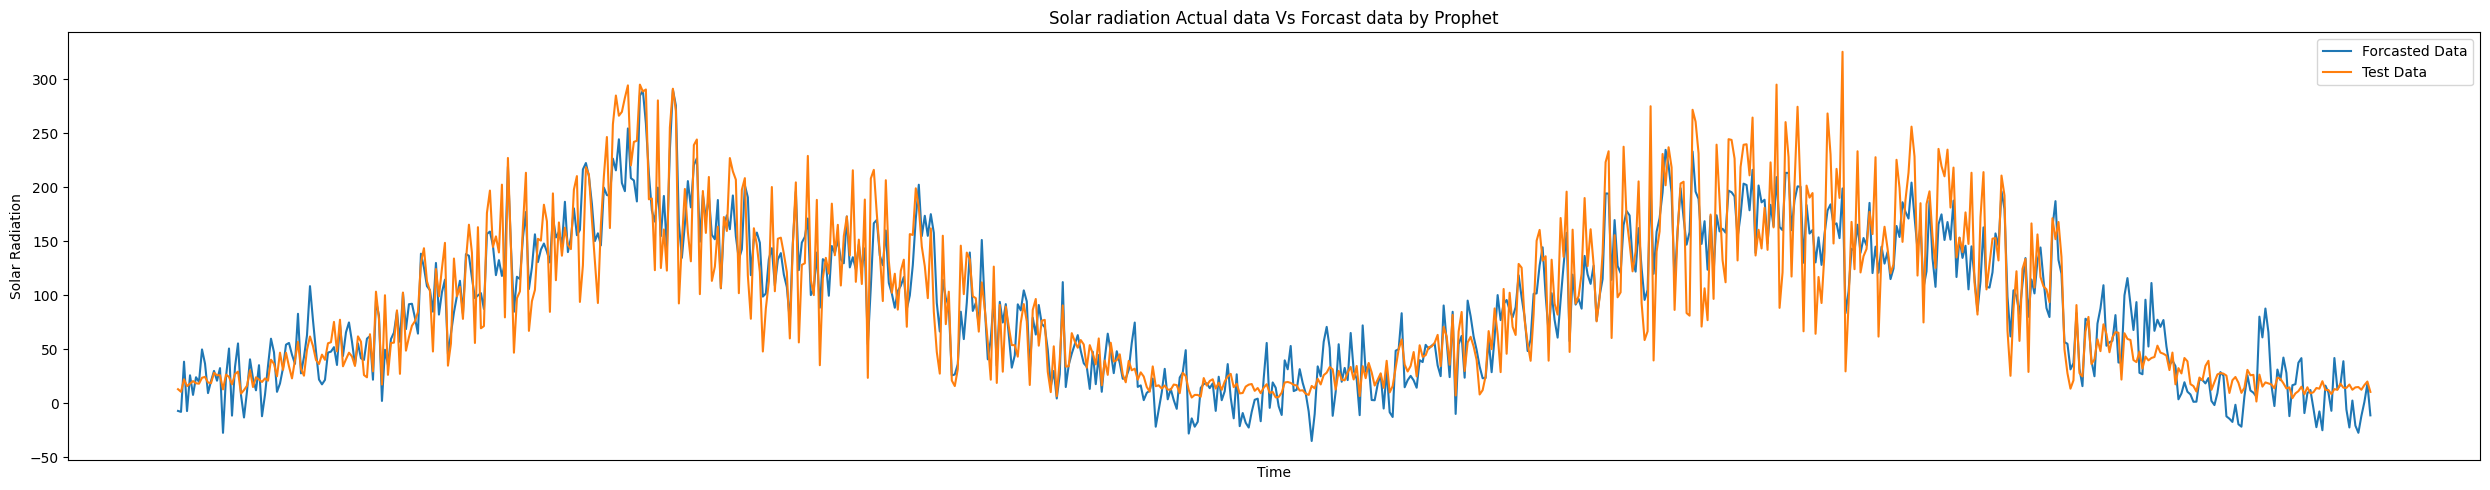

In [114]:
# Plot test data vs forecasted data
plt.figure(figsize=(25, 5))
plt.plot(test['ds'], predicted['yhat'], label='Forcasted Data')
plt.plot(test['ds'], test['y'], label='Test Data')
plt.title('Solar radiation Actual data Vs Forcast data by Prophet')
plt.xlabel('Time')
plt.ylabel('Solar Radiation')
plt.legend()
plt.grid(False)
plt.xticks(())
plt.tight_layout()
plt.show()

## Checking overfitting

Over fitting means the model gives low error on training but high error on test data. For Prophet, overfitting also make unrealistic seasonal patterns, following noise too closely in the training data.

In [116]:
train_pred = model.predict(train)

In [117]:
r2_train = r2_score(train['y'], train_pred['yhat'])
mae_train = mean_absolute_error(train['y'], train_pred['yhat'])
rmse_train = np.sqrt(mean_squared_error(train['y'], train_pred['yhat']))
mae_train,rmse_train

(25.91228618551997, np.float64(33.24056996967204))

In [118]:
print(f"Train RMSE: {rmse_train:.2f}",f"Train MAE: {mae_train:.4f}",f"Train R2 Score: {r2_train:.2f}")
print(f"Test  RMSE: {rmse:.2f}",f"Test MAE: {mae:.4f}",f"Test R2 Score: {r2:.2f}")

Train RMSE: 33.24 Train MAE: 25.9123 Train R2 Score: 0.82
Test  RMSE: 30.34 Test MAE: 23.3179 Test R2 Score: 0.83


Observations: Prophet model is not overfitting nor underfitting, RMSE and MAE are very close to each other. In addition, R2 score is very similar

## Train data and Predicted data Plot

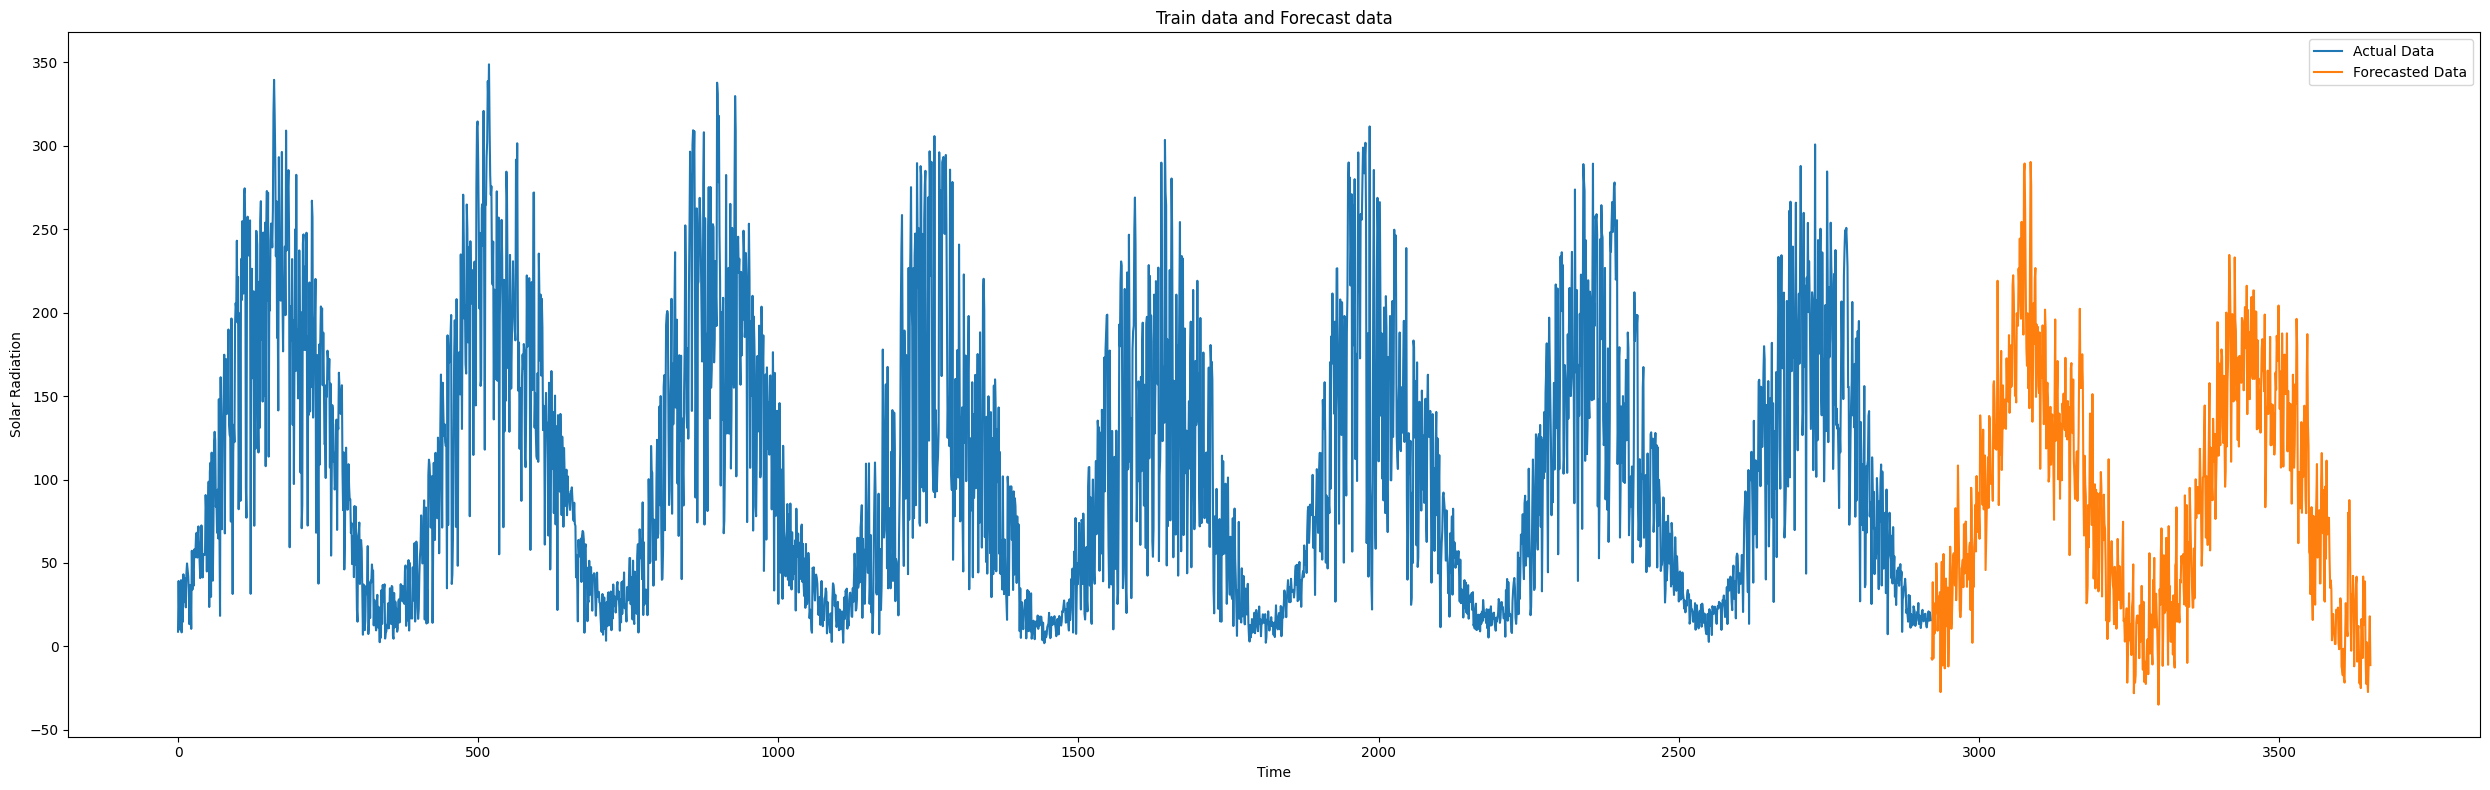

In [119]:
# Plotting training and predicted data
plt.figure(figsize=(25, 8))

# Plot actual historical data
plt.plot(train['ds'].index, train['y'],label='Actual Data')

# Plot forecasted data points
plt.plot(test['ds'].index, predicted['yhat'], label='Forecasted Data')


plt.title('Train data and Forecast data')
plt.xlabel('Time')
plt.ylabel('Solar Radiation')
plt.legend()
#plt.grid()
#plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


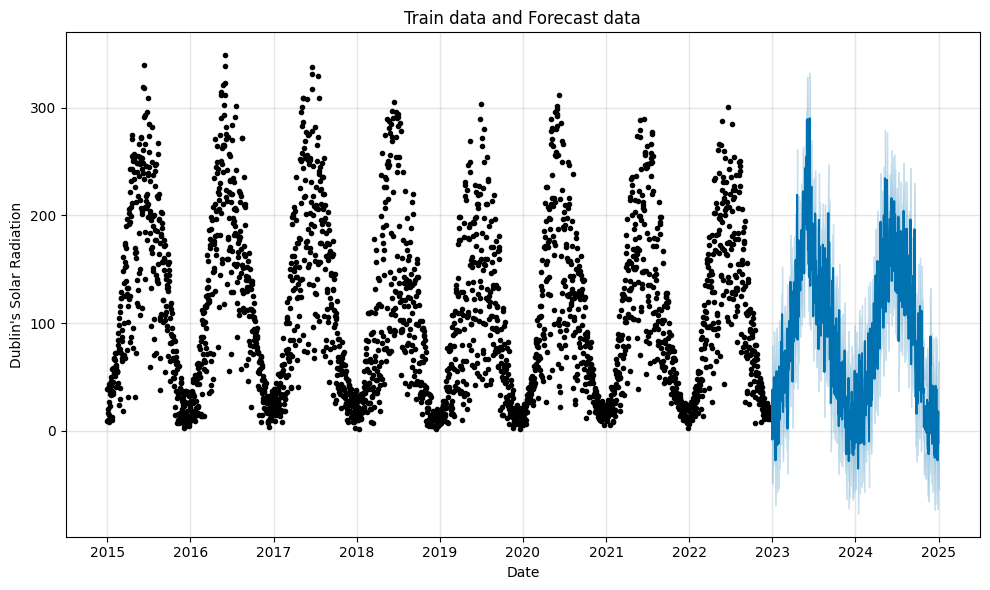

In [120]:
# Overall fit forecast by prophet plot
model.plot(predicted)


plt.title('Train data and Forecast data')
plt.xlabel('Date')
plt.ylabel("Dublin's Solar Radiation")

#plt.grid()
plt.xticks()
plt.tight_layout()
plt.show()

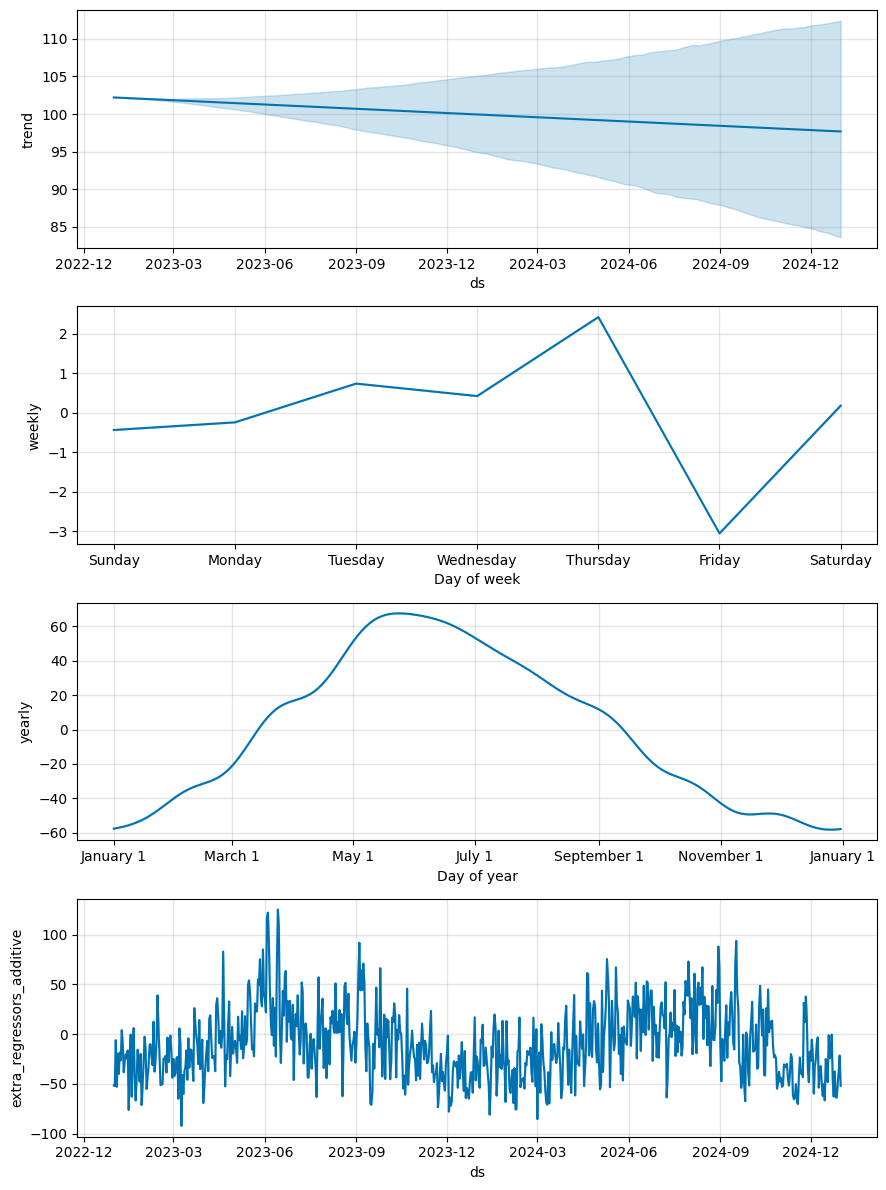

In [121]:
# Trend & seasonality components
model.plot_components(predicted)

plt.show()


## Hyperparameter Tuning



### Parameters Range

In [7]:
#function for random choice of parameters
def param_choice():
    return {
        'growth': 'linear',
        'seasonality_mode': random.choice(['additive', 'multiplicative']),
        'yearly_seasonality': random.choice([7, 10, 13, 16, 20]),
        'weekly_seasonality': random.choice([0, 3, 5, 7, 10]),
        'daily_seasonality': random.choice([0]),
        'changepoint_prior_scale': random.choice([0.001, 0.003, 0.01, 0.03, 0.1]),
        'changepoint_range': random.choice([0.80, 0.85, 0.90, 0.95]),
        'n_changepoints': random.choice([10, 15, 20, 24, 30, 40]),
        'seasonality_prior_scale': random.choice([0.5, 1, 2, 5, 10]),
        'holidays_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
        'regressor_mode': random.choice(['additive', 'multiplicative']),
        'regressor_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
    }

### Model 

In [8]:
#define model and score function
def fit_and_score(params):
    model_rs = Prophet(
        growth='linear',
        seasonality_mode=params['seasonality_mode'],
        yearly_seasonality=params['yearly_seasonality'],
        weekly_seasonality=params['weekly_seasonality'],
        daily_seasonality=params['daily_seasonality'],
        changepoint_prior_scale=params['changepoint_prior_scale'],
        changepoint_range=params['changepoint_range'],
        n_changepoints=params['n_changepoints'],
        seasonality_prior_scale=params['seasonality_prior_scale'],
        holidays_prior_scale=params['holidays_prior_scale'],
    )
    for col in X:
        model_rs.add_regressor(col, mode=params['regressor_mode'],
                            prior_scale=params['regressor_prior_scale'],
                            standardize='auto')

# model train
    model_rs.fit(train)

# model predictions   
    predicted_rs = model_rs.predict(test)

# y_true index and values
    y_true = test.set_index('ds').loc[test['ds'], 'y'].values

# score is mae
    score = mean_absolute_error(y_true, predicted_rs['yhat'].values)
    
    return score, model_rs, predicted_rs[['ds','yhat','yhat_lower','yhat_upper']]


## Randomized Search CV

Randomized search CV is a modeified version of Grid Search CV.The Random Search CV aims to find the best model parameters by training and evaluating the model for the specified number of iterations.

In [9]:
# Random search 
trails = 100 #epochs
best_score = np.inf
best = None

for i in range(1, trails+1):
    p = param_choice()
    try:
        score, model_rs, predicted_rs = fit_and_score(p)
        if score < best_score:
            best_score = score
            best = {'params': p, 'model': model_rs, 'forecast_test': predicted_rs, 'mae': score}
        print(f"Trial {i:02d}: MAE={score:.3f}  params={p}")
    except Exception as e:
        print(f"Trial {i:02d} failed: {e}")

print("\nBest MAE:", round(best['mae'], 3))
print("Best Params:", best['params'])

19:31:12 - cmdstanpy - INFO - Chain [1] start processing
19:31:12 - cmdstanpy - INFO - Chain [1] done processing


Trial 01: MAE=24.872  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 7, 'weekly_seasonality': 10, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.01, 'changepoint_range': 0.95, 'n_changepoints': 10, 'seasonality_prior_scale': 2, 'holidays_prior_scale': 10, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.3}


19:31:12 - cmdstanpy - INFO - Chain [1] start processing
19:31:13 - cmdstanpy - INFO - Chain [1] done processing


Trial 02: MAE=24.375  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 10, 'weekly_seasonality': 10, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.9, 'n_changepoints': 10, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 1, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 0.1}


19:31:13 - cmdstanpy - INFO - Chain [1] start processing
19:31:14 - cmdstanpy - INFO - Chain [1] done processing


Trial 03: MAE=23.274  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 7, 'weekly_seasonality': 0, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.03, 'changepoint_range': 0.85, 'n_changepoints': 15, 'seasonality_prior_scale': 2, 'holidays_prior_scale': 1, 'regressor_mode': 'additive', 'regressor_prior_scale': 3}


... (190 outputs left out)

19:32:51 - cmdstanpy - INFO - Chain [1] start processing
19:32:51 - cmdstanpy - INFO - Chain [1] done processing


Trial 99: MAE=23.165  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 13, 'weekly_seasonality': 0, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.9, 'n_changepoints': 30, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 3, 'regressor_mode': 'additive', 'regressor_prior_scale': 3}


19:32:52 - cmdstanpy - INFO - Chain [1] start processing
19:32:52 - cmdstanpy - INFO - Chain [1] done processing


Trial 100: MAE=23.828  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 20, 'weekly_seasonality': 3, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.01, 'changepoint_range': 0.95, 'n_changepoints': 30, 'seasonality_prior_scale': 2, 'holidays_prior_scale': 3, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 10}

Best MAE: 22.799
Best Params: {'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 16, 'weekly_seasonality': 5, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.003, 'changepoint_range': 0.8, 'n_changepoints': 15, 'seasonality_prior_scale': 5, 'holidays_prior_scale': 3, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.3}


### Best parameters

In [10]:
print("Best Params:", best['params'])

Best Params: {'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 16, 'weekly_seasonality': 5, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.003, 'changepoint_range': 0.8, 'n_changepoints': 15, 'seasonality_prior_scale': 5, 'holidays_prior_scale': 3, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.3}


## Building the Model with best parameters

In [43]:
model_best= Prophet(
    growth= 'linear',
    seasonality_mode= 'additive',
    yearly_seasonality= 16,
    weekly_seasonality= 5,
    daily_seasonality= 0, 
    changepoint_prior_scale= 0.003,
    changepoint_range= 0.8,
    n_changepoints= 15,
    seasonality_prior_scale= 5,
    holidays_prior_scale= 3,

                )




for x in X:
    model_best.add_regressor(x, mode='additive', prior_scale=0.3, standardize='auto')



In [44]:
model_best.fit(train)

19:29:15 - cmdstanpy - INFO - Chain [1] start processing
19:29:15 - cmdstanpy - INFO - Chain [1] done processing


## Predict

In [45]:
predicted_best=model_best.predict(test)

## Accuracy of the Model with Best parameters

In [14]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['y'], predicted_best['yhat']))
mae = mean_absolute_error(test['y'], predicted_best['yhat'])
r2 = r2_score(test['y'], predicted_best['yhat'])
mape=mean_absolute_percentage_error(test['y'], predicted_best['yhat'])

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 29.9600
MAE: 22.7991
R² Score: 0.8389
MAPE: 0.4812


In [36]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [37]:
print("SMAPE:", smape(test['y'], predicted_best['yhat']))

SMAPE: 42.41374288061846


## Plot Test vs Forecast

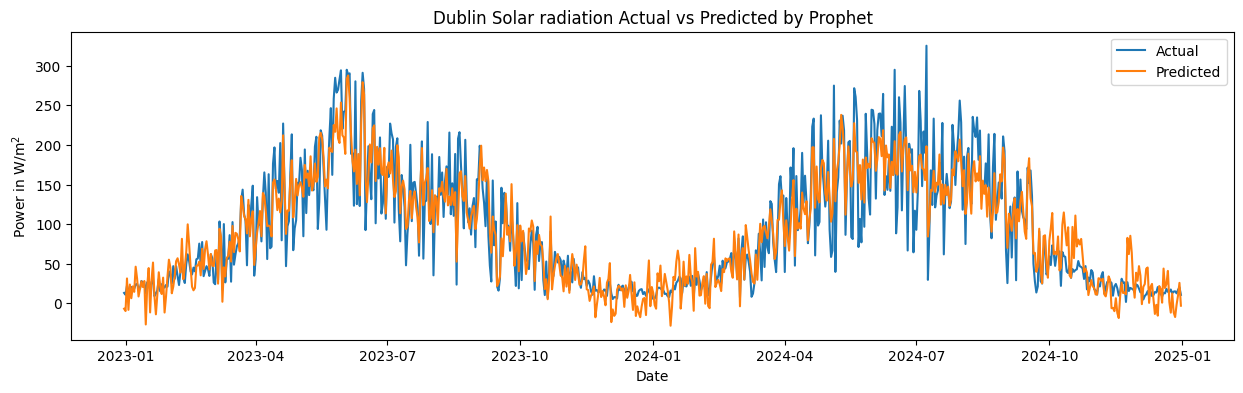

In [28]:
# Plot test data vs forecasted data
plt.figure(figsize=(15, 4))
plt.plot(test['ds'], test['y'], label='Actual')
plt.plot(test['ds'], predicted_best['yhat'], label='Predicted')

plt.title('Dublin Solar radiation Actual vs Predicted by Prophet')
plt.ylabel('Power in W/m$^2$')
plt.xlabel('Date')
plt.legend()
plt.savefig('test_vs_forecast_prophet')
plt.show()

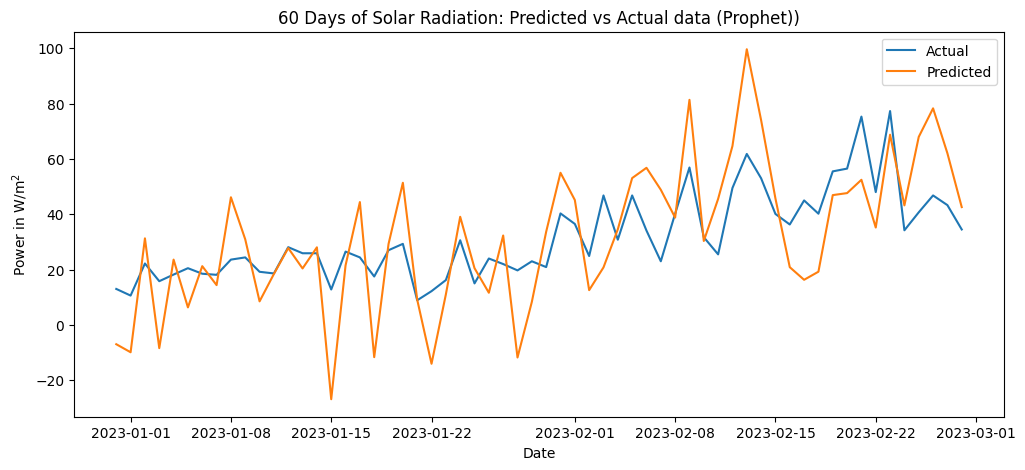

In [83]:
plt.figure(figsize=(12,5))
plt.plot(test['ds'][:60],test['y'][:60], label="Actual")
plt.plot(test['ds'][:60],predicted_best['yhat'][:60], label="Predicted")
plt.legend()
plt.title("60 Days of Solar Radiation: Predicted vs Actual data (Prophet))")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

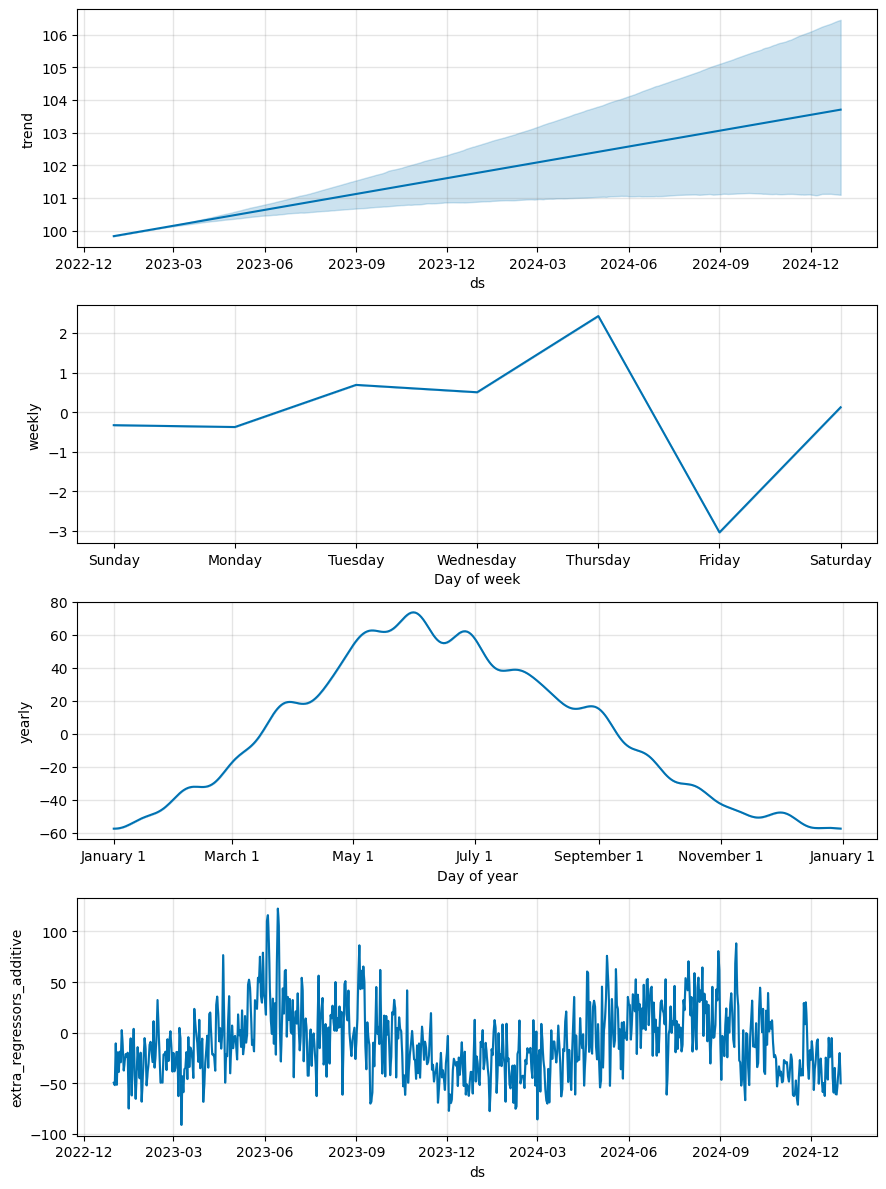

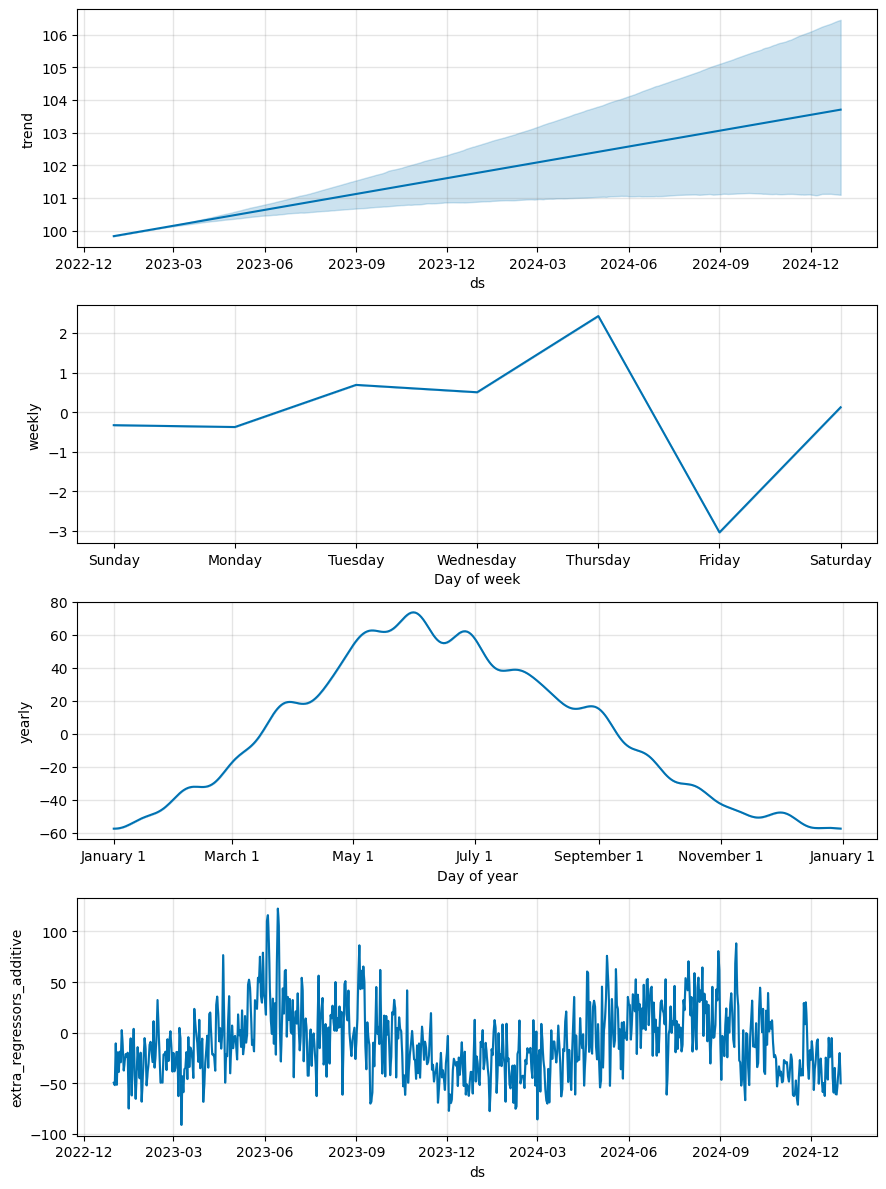

In [51]:
model_best.plot_components(predicted_best)

### Residuals

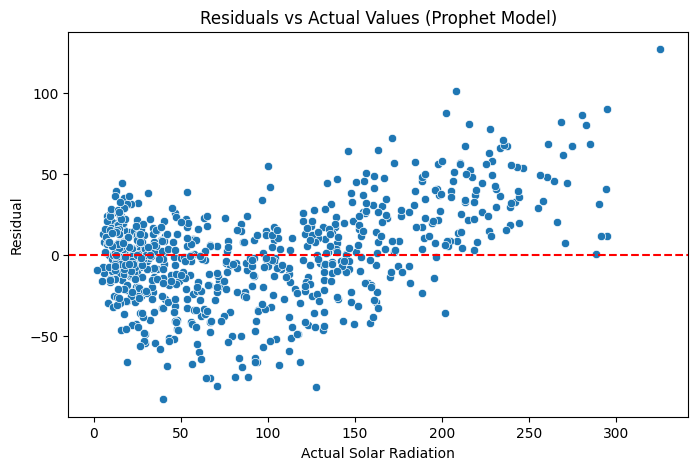

In [81]:
y = test['y'].to_numpy()
yhat = predicted_best['yhat'].to_numpy()

residuals = y - yhat

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y, y=residuals)
plt.axhline(0, color='red',linestyle='--')
plt.xlabel("Actual Solar Radiation")
plt.ylabel("Residual")
plt.title("Residuals vs Actual Values (Prophet Model)")
plt.show()


# Experiment 2:
To develop a Prophet Model applying **differencing** to the target feature.

### Import Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Prophet model
from prophet import Prophet

# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#random seachcv
from sklearn.model_selection import RandomizedSearchCV
import random

## Load Dataset

In [29]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Differencing technique

In [30]:
df['solarradiation_diff'] = df['solarradiation'].diff()

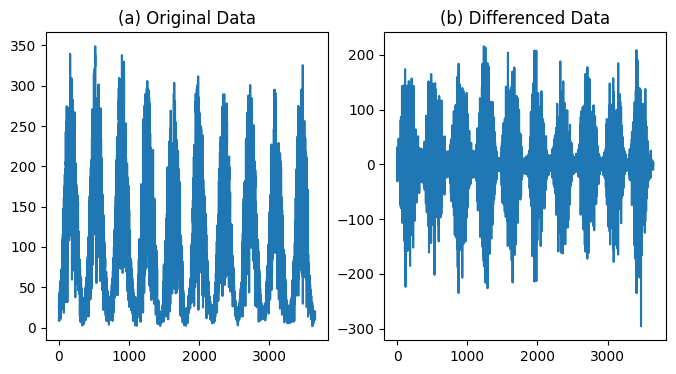

In [31]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
plt.plot(df['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
plt.plot(df['solarradiation_diff'])
plt.title("(b) Differenced Data")
plt.show()

In [32]:
df=df.drop('solarradiation',axis=1)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   datetime             3653 non-null   datetime64[ns]
 1   tempmax              3653 non-null   float64       
 2   humidity             3653 non-null   float64       
 3   precip               3653 non-null   float64       
 4   windgust             3653 non-null   float64       
 5   windspeed            3653 non-null   float64       
 6   winddir              3653 non-null   float64       
 7   sealevelpressure     3653 non-null   float64       
 8   cloudcover           3653 non-null   float64       
 9   visibility           3653 non-null   float64       
 10  solarradiation_diff  3652 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 314.1 KB


### Prophet model's data processing

Prophet models require a column called 'ds' for time, and 'y' for the target feature


In [34]:
# Rename columns as Prophet expects
df = df.rename(columns={'datetime': 'ds', 'solarradiation_diff': 'y'})
df = df.dropna()

Adittionally, the exogenous variables have to be defined into a list

In [8]:
df.columns

Index(['ds', 'tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'y'],
      dtype='object')

In [35]:
# Define Exogenous data or regressors
X =['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility']

In [140]:
df.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,30.4
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,-22.3
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,3.2
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,-10.3
5,2015-01-06,9.7,84.4,0.712,64.8,36.5,227.5,1017.0,59.8,22.7,29.9


### Split data into 80/20

Creating the features for training and testing prophet model

In [36]:
# Separate historical and future data
train = df[df['ds'] < '2022-12-31']
test = df[df['ds'] >= '2022-12-31'].copy()

In [13]:
train.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,30.4
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,-22.3
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,3.2
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,-10.3
5,2015-01-06,9.7,84.4,0.712,64.8,36.5,227.5,1017.0,59.8,22.7,29.9


In [14]:
test.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
2921,2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,-2.7
2922,2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,-2.4
2923,2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,11.6
2924,2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,-6.4
2925,2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,2.4


## Building the Model

In [188]:
# Initialize Prophet model
model = Prophet(yearly_seasonality=True,
    weekly_seasonality=True,
    changepoint_prior_scale=0.1,       # allow more trend flexibility
    seasonality_prior_scale=20.0, )     # allow stronger seasonal variation)

In [189]:
# add regressors (exogenous variables)

for x in X:
    model.add_regressor(x, standardize='auto')

In [190]:
# checking for exogenous variables that the model expects
print("Model expects:", list(model.extra_regressors.keys()))


Model expects: ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility']


### Fit the model

In [191]:
# Fit the model using train data
model.fit(train)

21:53:51 - cmdstanpy - INFO - Chain [1] start processing
21:53:51 - cmdstanpy - INFO - Chain [1] done processing


### Predict values

In [192]:
predicted=model.predict(test)

Prophet model shows the predicted values in 'yhat' feature

In [56]:
predicted.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,cloudcover,...,windspeed,windspeed_lower,windspeed_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2022-12-31,3.973738,-64.630810,65.736289,3.973738,3.973738,-5.538150,-5.538150,-5.538150,-16.719803,...,-7.765725,-7.765725,-7.765725,14.168364,14.168364,14.168364,0.0,0.0,0.0,-1.564412
1,2023-01-01,3.980137,-72.033529,61.527107,3.980137,3.980137,-8.975590,-8.975590,-8.975590,-7.994590,...,-5.531656,-5.531656,-5.531656,14.191450,14.191450,14.191450,0.0,0.0,0.0,-4.995454
2,2023-01-02,3.986535,-45.530368,85.046408,3.986535,3.986535,14.131421,14.131421,14.131421,13.919896,...,-1.771879,-1.771879,-1.771879,14.210476,14.210476,14.210476,0.0,0.0,0.0,18.117956
3,2023-01-03,3.992934,-70.086758,58.084449,3.992934,3.992934,-13.327294,-13.327294,-13.327294,-14.758321,...,4.330946,4.330946,4.330946,14.225683,14.225683,14.225683,0.0,0.0,0.0,-9.334361
4,2023-01-04,3.999332,-58.468044,72.599697,3.999332,3.999332,4.583238,4.583238,4.583238,-8.062228,...,3.840540,3.840540,3.840540,14.237669,14.237669,14.237669,0.0,0.0,0.0,8.582570


## Undo differencing

In [195]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [196]:
# last actual value before test starts
last_train_value = df.loc['2022-12-29', 'solarradiation']

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(predicted['yhat'])

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)

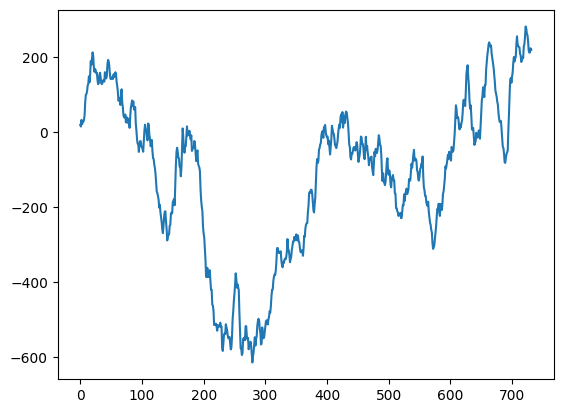

In [197]:
plt.plot(y_pred_original)

### Accuracy

In order to make a comparison of the models' performance, a systematic analysis of statistical evaluation metrics, including the R² score, Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE) is cumputed.

In [198]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['y'], y_pred_original))
mae = mean_absolute_error(test['y'], y_pred_original)
r2 = r2_score(test['y'], y_pred_original)
mape = mean_absolute_percentage_error(test['y'], y_pred_original)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape:4f}")

RMSE: 252.5276
MAE: 191.4734
R² Score: -20.5167
MAPE: 10145855308048526.000000


In [199]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [200]:
print("SMAPE:", smape(test['y'], y_pred_original))

SMAPE: 165.69985427234195


### Plot Actual vs Predicted

In [201]:
train_org = df[df.index < '2022-12-31']
test_org = df[df.index >= '2022-12-31'].copy()

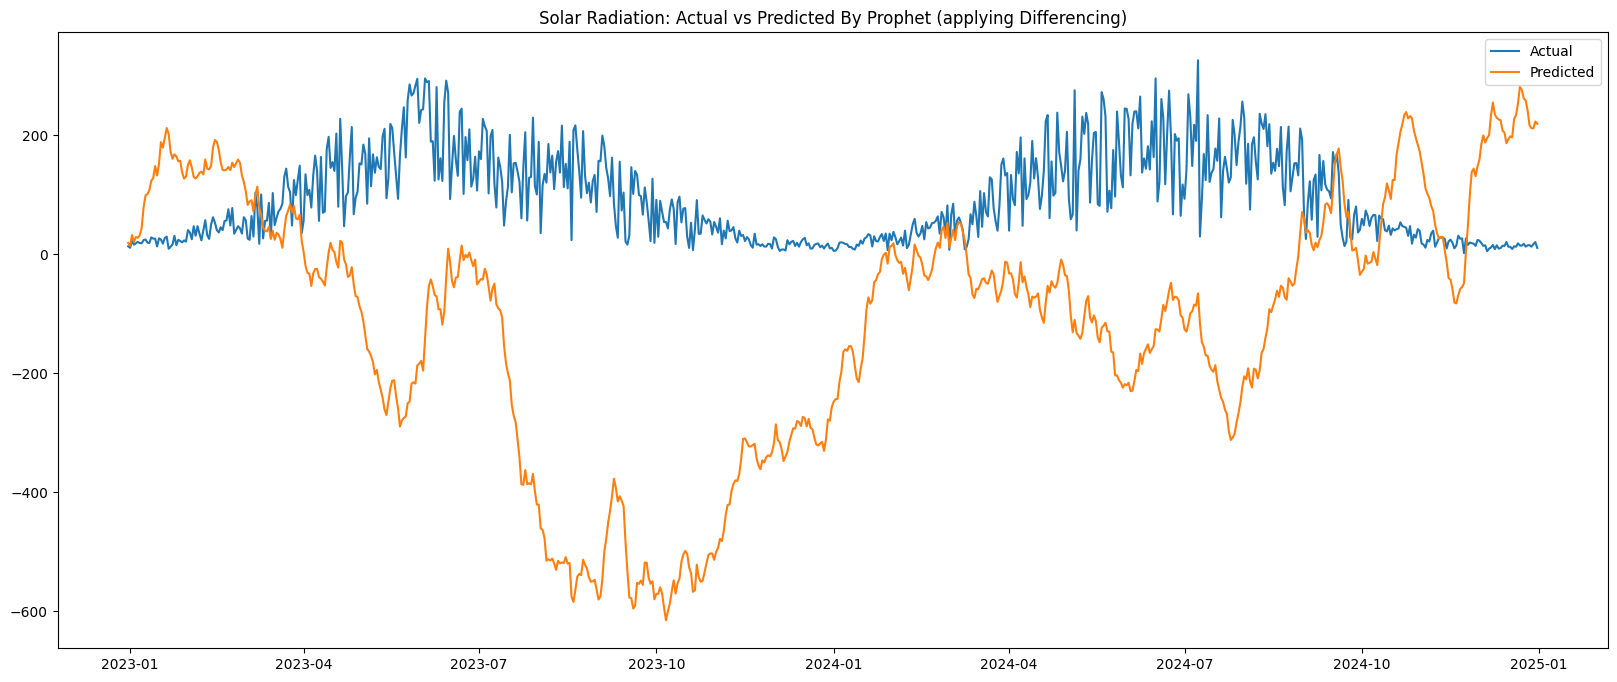

In [202]:
plt.figure(figsize=(20,8))
plt.plot(test_org.index,test_org['solarradiation'], label="Actual")
plt.plot(test_org.index,y_pred_original, label="Predicted")
plt.legend()
plt.title("Solar Radiation: Actual vs Predicted By Prophet (applying Differencing)")
plt.show()

## Hyperparameter Tuning



### Parameters Range

In [37]:
#function for random choice of parameters
def param_choice():
    return {
        'growth': 'linear',
        'seasonality_mode': random.choice(['additive', 'multiplicative']),
        'yearly_seasonality': random.choice([7, 10, 13, 16, 20]),
        'weekly_seasonality': random.choice([0, 3, 5, 7, 10]),
        'daily_seasonality': random.choice([0]),
        'changepoint_prior_scale': random.choice([0.001, 0.003, 0.01, 0.03, 0.1]),
        'changepoint_range': random.choice([0.80, 0.85, 0.90, 0.95]),
        'n_changepoints': random.choice([10, 15, 20, 24, 30, 40]),
        'seasonality_prior_scale': random.choice([0.5, 1, 2, 5, 10]),
        'holidays_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
        'regressor_mode': random.choice(['additive', 'multiplicative']),
        'regressor_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
    }

### Model 

In [38]:
#define model and score function
def fit_and_score(params):
    model_rs = Prophet(
        growth='linear',
        seasonality_mode=params['seasonality_mode'],
        yearly_seasonality=params['yearly_seasonality'],
        weekly_seasonality=params['weekly_seasonality'],
        daily_seasonality=params['daily_seasonality'],
        changepoint_prior_scale=params['changepoint_prior_scale'],
        changepoint_range=params['changepoint_range'],
        n_changepoints=params['n_changepoints'],
        seasonality_prior_scale=params['seasonality_prior_scale'],
        holidays_prior_scale=params['holidays_prior_scale'],
    )
    for col in X:
        model_rs.add_regressor(col, mode=params['regressor_mode'],
                            prior_scale=params['regressor_prior_scale'],
                            standardize='auto')

# model train
    model_rs.fit(train)

# model predictions   
    predicted_rs = model_rs.predict(test)

# y_true index and values
    y_true = test.set_index('ds').loc[test['ds'], 'y'].values

# score is mae
    score = mean_absolute_error(y_true, predicted_rs['yhat'].values)
    
    return score, model_rs, predicted_rs[['ds','yhat','yhat_lower','yhat_upper']]


## Randomized Search CV

Randomized search CV is a modeified version of Grid Search CV.The Random Search CV aims to find the best model parameters by training and evaluating the model for the specified number of iterations.

In [48]:
# Random search 
trails = 100 #epochs
best_score = np.inf
best = None

for i in range(1, trails+1):
    p = param_choice()
    try:
        score, model_rs, predicted_rs = fit_and_score(p)
        if score < best_score:
            best_score = score
            best = {'params': p, 'model': model_rs, 'forecast_test': predicted_rs, 'mae': score}
        print(f"Trial {i:02d}: MAE={score:.3f}  params={p}")
    except Exception as e:
        print(f"Trial {i:02d} failed: {e}")

print("\nBest MAE:", round(best['mae'], 3))
print("Best Params:", best['params'])

19:56:46 - cmdstanpy - INFO - Chain [1] start processing
19:56:46 - cmdstanpy - INFO - Chain [1] done processing


Trial 01: MAE=35.731  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 20, 'weekly_seasonality': 7, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.03, 'changepoint_range': 0.95, 'n_changepoints': 40, 'seasonality_prior_scale': 0.5, 'holidays_prior_scale': 3, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.3}


19:56:46 - cmdstanpy - INFO - Chain [1] start processing
19:56:47 - cmdstanpy - INFO - Chain [1] done processing


Trial 02: MAE=35.617  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 13, 'weekly_seasonality': 7, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.85, 'n_changepoints': 40, 'seasonality_prior_scale': 10, 'holidays_prior_scale': 0.1, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 1}


19:56:47 - cmdstanpy - INFO - Chain [1] start processing
19:56:48 - cmdstanpy - INFO - Chain [1] done processing


Trial 03: MAE=43.824  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 16, 'weekly_seasonality': 7, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.001, 'changepoint_range': 0.8, 'n_changepoints': 40, 'seasonality_prior_scale': 2, 'holidays_prior_scale': 3, 'regressor_mode': 'additive', 'regressor_prior_scale': 10}


... (190 outputs left out)

19:58:17 - cmdstanpy - INFO - Chain [1] start processing
19:58:17 - cmdstanpy - INFO - Chain [1] done processing


Trial 99: MAE=40.801  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 16, 'weekly_seasonality': 10, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.001, 'changepoint_range': 0.85, 'n_changepoints': 15, 'seasonality_prior_scale': 0.5, 'holidays_prior_scale': 1, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.1}


19:58:18 - cmdstanpy - INFO - Chain [1] start processing
19:58:18 - cmdstanpy - INFO - Chain [1] done processing


Trial 100: MAE=36.238  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 20, 'weekly_seasonality': 0, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.003, 'changepoint_range': 0.85, 'n_changepoints': 10, 'seasonality_prior_scale': 5, 'holidays_prior_scale': 1, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 1}

Best MAE: 34.822
Best Params: {'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 20, 'weekly_seasonality': 3, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.85, 'n_changepoints': 15, 'seasonality_prior_scale': 5, 'holidays_prior_scale': 0.3, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 1}


### Best parameters

In [49]:
print("Best Params:", best['params'])

Best Params: {'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 20, 'weekly_seasonality': 3, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.85, 'n_changepoints': 15, 'seasonality_prior_scale': 5, 'holidays_prior_scale': 0.3, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 1}


## Building the Model with best parameters

In [50]:
model_best= Prophet(
    growth= 'linear',
    seasonality_mode= 'multiplicative',
    yearly_seasonality= 20,
    weekly_seasonality= 3,
    daily_seasonality= 0, 
    changepoint_prior_scale= 0.1,
    changepoint_range= 0.85,
    n_changepoints= 15,
    seasonality_prior_scale= 5,
    holidays_prior_scale= 0.3,

                )

for x in X:
    model_best.add_regressor(x, mode='multiplicative', prior_scale=1, standardize='auto')



In [51]:
model_best.fit(train)

19:59:56 - cmdstanpy - INFO - Chain [1] start processing
19:59:57 - cmdstanpy - INFO - Chain [1] done processing


## Predict

In [52]:
predicted_best=model_best.predict(test)

## Undo differencing

In [53]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [54]:
# last actual value before test starts
last_train_value = df.loc['2022-12-29', 'solarradiation']

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(predicted_best['yhat'])

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)

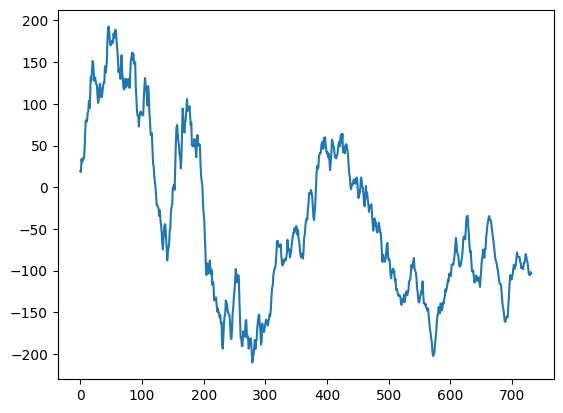

In [55]:
plt.plot(y_pred_original)

### Accuracy

In order to make a comparison of the models' performance, a systematic analysis of statistical evaluation metrics, including the R² score, Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE) is cumputed.

In [62]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['y'], y_pred_original))
mae = mean_absolute_error(test['y'], y_pred_original)
r2 = r2_score(test['y'], y_pred_original)
mape = mean_absolute_percentage_error(test['y'], y_pred_original)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape:4f}")

RMSE: 119.6557
MAE: 100.8616
R² Score: -3.8309
MAPE: 3567985277043801.000000


In [63]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [64]:
print("SMAPE:", smape(test['y'], y_pred_original))

SMAPE: 159.09448049502237


### Plot Actual vs Predicted

In [58]:
train_org = df[df.index < '2022-12-31']
test_org = df[df.index >= '2022-12-31'].copy()

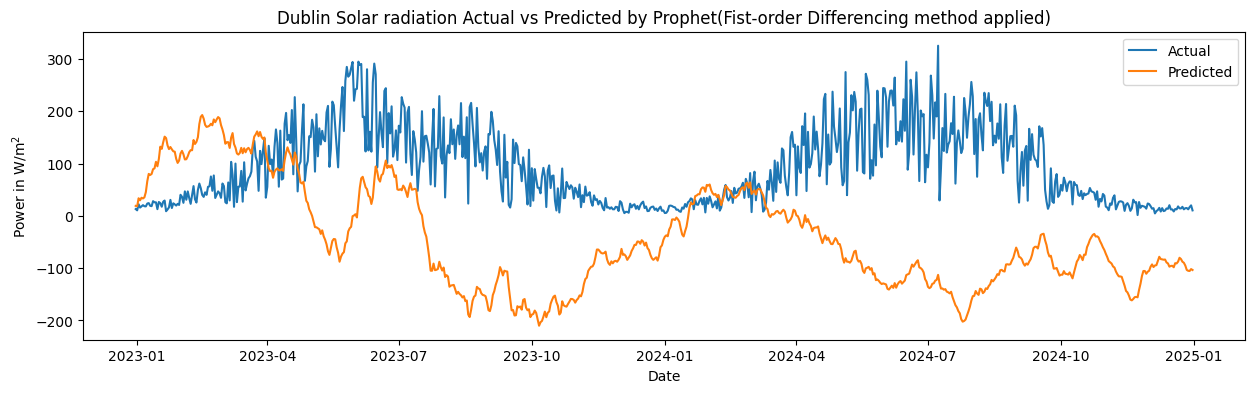

In [61]:
plt.figure(figsize=(15,4))
plt.plot(test_org.index,test_org['solarradiation'], label="Actual")
plt.plot(test_org.index,y_pred_original, label="Predicted")
plt.legend()
plt.title("Dublin Solar radiation Actual vs Predicted by Prophet(Fist-order Differencing method applied)")
plt.ylabel('Power in W/m$^2$')
plt.xlabel('Date')
plt.legend()
plt.show()

# Experiment 3:
To develop a Prophet Model for forecasting task applying **log transformation** technique to the target feature (solarradiation).

### Import Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Prophet model
from prophet import Prophet

# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#random seachcv
from sklearn.model_selection import RandomizedSearchCV
import random

## Load Dataset

In [65]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Natural logarithmic transformation

the original solar radiation variable exhibited a highly right-skewed distribution, with most values close to zero and few large peaks corresponding to maximum sunlight hours. To normalize the distribution and stabilize variance, a natural logarithmic transformation 𝑦′=ln(1+𝑦) was applied.

Best practice in statistics: The use of log transformation (West, 2021) emphasises that log-transforming a right-skewed positive variable can help make distributions more symmetric.

In [66]:
df['solarradiation_log'] = np.log1p(df['solarradiation'])

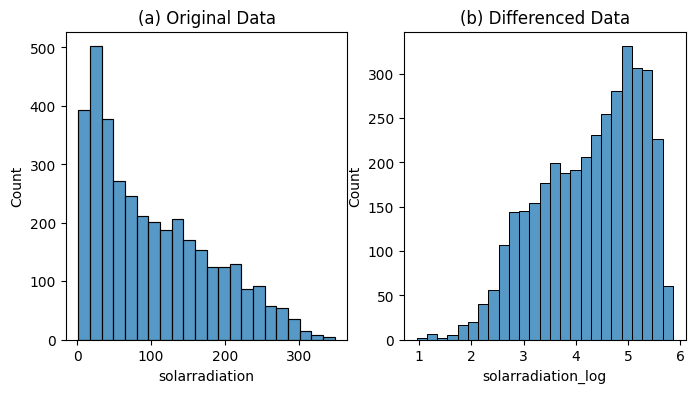

In [67]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
sns.histplot(df['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
sns.histplot(df['solarradiation_log'])
plt.title("(b) Differenced Data")
plt.show()

In [68]:
df=df.drop('solarradiation',axis=1)

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   datetime            3653 non-null   datetime64[ns]
 1   tempmax             3653 non-null   float64       
 2   humidity            3653 non-null   float64       
 3   precip              3653 non-null   float64       
 4   windgust            3653 non-null   float64       
 5   windspeed           3653 non-null   float64       
 6   winddir             3653 non-null   float64       
 7   sealevelpressure    3653 non-null   float64       
 8   cloudcover          3653 non-null   float64       
 9   visibility          3653 non-null   float64       
 10  solarradiation_log  3653 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 314.1 KB


### Prophet model's data processing

Prophet models require a column called 'ds' for time, and 'y' for the target feature


In [70]:
# Rename columns as Prophet expects
df = df.rename(columns={'datetime': 'ds', 'solarradiation_log': 'y'})
df = df.dropna()

Adittionally, the exogenous variables have to be defined into a list

In [14]:
df.columns

Index(['ds', 'tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'y'],
      dtype='object')

In [71]:
# Define Exogenous data or regressors
X =['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility']

In [15]:
df.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,2.282382
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,3.693867
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,2.884801
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,3.049273
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,2.379546


### Split data into 80/20

Creating the features for training and testing prophet model

In [72]:
# Separate historical and future data
train = df[df['ds'] < '2022-12-31']
test = df[df['ds'] >= '2022-12-31'].copy()

In [163]:
train.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,2.282382
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,3.693867
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,2.884801
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,3.049273
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,2.379546


In [14]:
test.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
2921,2022-12-31,9.9,93.0,1.523,23.4,13.8,212.2,991.8,89.9,13.4,-2.7
2922,2023-01-01,6.8,91.8,0.735,36.4,17.9,241.6,1000.4,77.0,15.2,-2.4
2923,2023-01-02,5.9,84.8,0.000,46.1,24.8,222.7,1014.4,44.6,15.6,11.6
2924,2023-01-03,13.0,85.1,0.849,78.1,36.0,202.6,1004.4,87.0,16.6,-6.4
2925,2023-01-04,12.8,79.4,0.314,64.8,35.1,252.6,1008.0,77.1,15.7,2.4


## Building the Model

In [209]:
# Initialize Prophet model
model = Prophet(yearly_seasonality=True,
    weekly_seasonality=True,
    changepoint_prior_scale=0.1,       # allow more trend flexibility
    seasonality_prior_scale=20.0, )     # allow stronger seasonal variation)

In [210]:
# add regressors (exogenous variables)

for x in X:
    model.add_regressor(x, standardize='auto')

In [211]:
# checking for exogenous variables that the model expects
print("Model expects:", list(model.extra_regressors.keys()))


Model expects: ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility']


### Fit the model

In [212]:
# Fit the model using train data
model.fit(train)

21:55:33 - cmdstanpy - INFO - Chain [1] start processing
21:55:33 - cmdstanpy - INFO - Chain [1] done processing


### Predict values

In [213]:
predicted=model.predict(test)

Prophet model shows the predicted values in 'yhat' feature

In [22]:
predicted.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,cloudcover,...,windspeed,windspeed_lower,windspeed_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2022-12-31,4.310825,2.180905,3.055318,4.310825,4.310825,-1.691426,-1.691426,-1.691426,-0.297367,...,-0.022987,-0.022987,-0.022987,-1.241080,-1.241080,-1.241080,0.0,0.0,0.0,2.619399
1,2023-01-01,4.310768,2.330806,3.207181,4.310768,4.310768,-1.555537,-1.555537,-1.555537,-0.142141,...,-0.016380,-0.016380,-0.016380,-1.228012,-1.228012,-1.228012,0.0,0.0,0.0,2.755231
2,2023-01-02,4.310711,2.716118,3.662839,4.310711,4.310711,-1.124375,-1.124375,-1.124375,0.247728,...,-0.005260,-0.005260,-0.005260,-1.214397,-1.214397,-1.214397,0.0,0.0,0.0,3.186336
3,2023-01-03,4.310655,2.220442,3.092520,4.310655,4.310655,-1.660316,-1.660316,-1.660316,-0.262471,...,0.012789,0.012789,0.012789,-1.200309,-1.200309,-1.200309,0.0,0.0,0.0,2.650339
4,2023-01-04,4.310598,2.516679,3.466100,4.310598,4.310598,-1.337624,-1.337624,-1.337624,-0.143345,...,0.011339,0.011339,0.011339,-1.185808,-1.185808,-1.185808,0.0,0.0,0.0,2.972974


### Undo log transform

In [214]:
y_pred_real = np.expm1(predicted['yhat'])

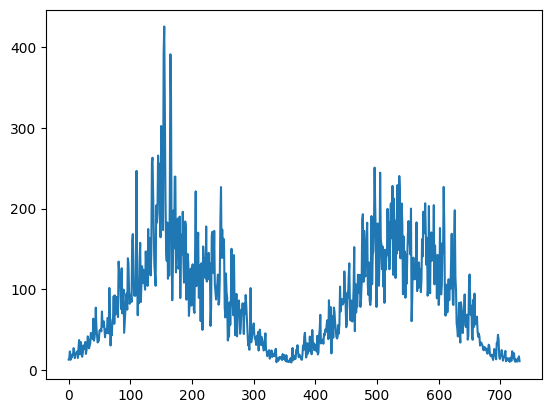

In [215]:
plt.plot(y_pred_real)

### Accuracy

In order to make a comparison of the models' performance, a systematic analysis of statistical evaluation metrics, including the R² score, Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE) is cumputed.

In [216]:
df_org=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df_org = df_org.rename(columns={'datetime': 'ds', 'solarradiation': 'y'})
test_org = df_org[df_org['ds'] >= '2022-12-31']

In [176]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['y'], y_pred_real))
mae = mean_absolute_error(test_org['y'], y_pred_real)
r2 = r2_score(test_org['y'], y_pred_real)
mape = mean_absolute_percentage_error(test_org['y'], y_pred_real)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape:4f}")

RMSE: 32.0362
MAE: 21.6940
R² Score: 0.8157
MAPE: 0.323404


In [177]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [178]:
print("SMAPE:", smape(test_org['y'], y_pred_real))

SMAPE: 26.950996585321718


### Plot Actual vs Predicted

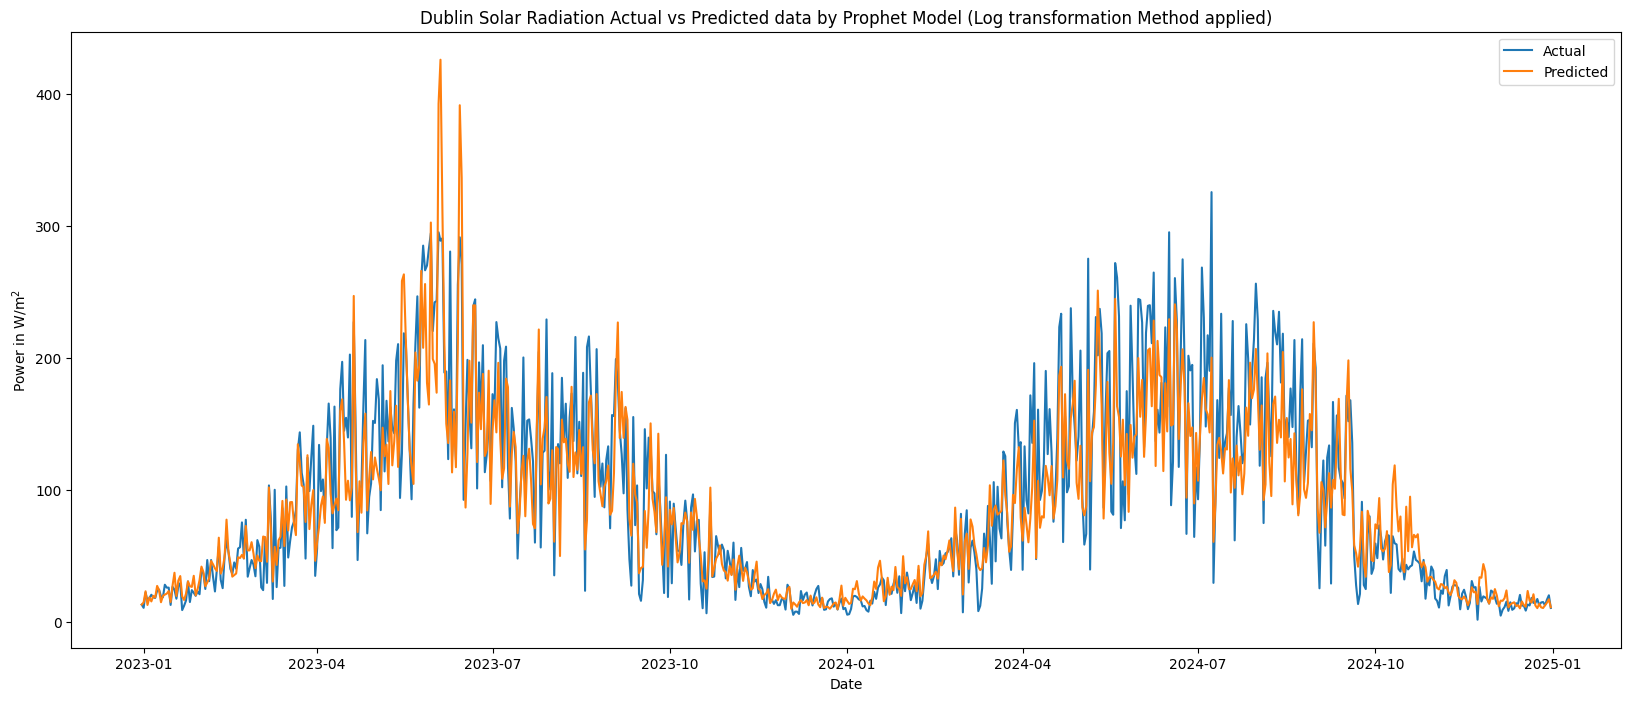

In [325]:
plt.figure(figsize=(20,8))
plt.plot(test_org['ds'],test_org['y'], label="Actual")
plt.plot(test_org['ds'],y_pred_real, label="Predicted")
plt.legend()
plt.title("Dublin Solar Radiation Actual vs Predicted data by Prophet Model (Log transformation Method applied)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

### Actual vs Predicted 60 days plot

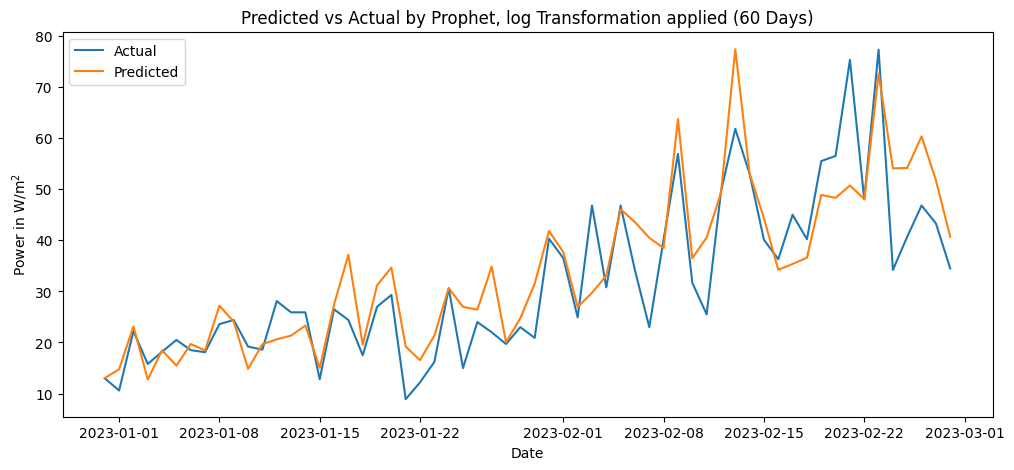

In [326]:
plt.figure(figsize=(12,5))
plt.plot(test_org['ds'][:60],test_org['y'][:60], label="Actual")
plt.plot(test_org['ds'][:60],y_pred_real[:60], label="Predicted")
plt.legend()
plt.title("Predicted vs Actual by Prophet, log Transformation applied (60 Days)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

## Hyperparameter Tuning



### Parameters Range

In [73]:
#function for random choice of parameters
def param_choice():
    return {
        'growth': 'linear',
        'seasonality_mode': random.choice(['additive', 'multiplicative']),
        'yearly_seasonality': random.choice([7, 10, 13, 16, 20]),
        'weekly_seasonality': random.choice([0, 3, 5, 7, 10]),
        'daily_seasonality': random.choice([0]),
        'changepoint_prior_scale': random.choice([0.001, 0.003, 0.01, 0.03, 0.1]),
        'changepoint_range': random.choice([0.80, 0.85, 0.90, 0.95]),
        'n_changepoints': random.choice([10, 15, 20, 24, 30, 40]),
        'seasonality_prior_scale': random.choice([0.5, 1, 2, 5, 10]),
        'holidays_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
        'regressor_mode': random.choice(['additive', 'multiplicative']),
        'regressor_prior_scale': random.choice([0.1, 0.3, 1, 3, 10]),
    }

### Model 

In [74]:
#define model and score function
def fit_and_score(params):
    model_rs = Prophet(
        growth='linear',
        seasonality_mode=params['seasonality_mode'],
        yearly_seasonality=params['yearly_seasonality'],
        weekly_seasonality=params['weekly_seasonality'],
        daily_seasonality=params['daily_seasonality'],
        changepoint_prior_scale=params['changepoint_prior_scale'],
        changepoint_range=params['changepoint_range'],
        n_changepoints=params['n_changepoints'],
        seasonality_prior_scale=params['seasonality_prior_scale'],
        holidays_prior_scale=params['holidays_prior_scale'],
    )
    for col in X:
        model_rs.add_regressor(col, mode=params['regressor_mode'],
                            prior_scale=params['regressor_prior_scale'],
                            standardize='auto')

# model train
    model_rs.fit(train)

# model predictions   
    predicted_rs = model_rs.predict(test)

# y_true index and values
    y_true = test.set_index('ds').loc[test['ds'], 'y'].values

# score is mae
    score = mean_absolute_error(y_true, predicted_rs['yhat'].values)
    
    return score, model_rs, predicted_rs[['ds','yhat','yhat_lower','yhat_upper']]


## Randomized Search CV

Randomized search CV is a modeified version of Grid Search CV.The Random Search CV aims to find the best model parameters by training and evaluating the model for the specified number of iterations.

In [75]:
# Random search 
trails = 100 #epochs
best_score = np.inf
best = None

for i in range(1, trails+1):
    p = param_choice()
    try:
        score, model_rs, predicted_rs = fit_and_score(p)
        if score < best_score:
            best_score = score
            best = {'params': p, 'model': model_rs, 'forecast_test': predicted_rs, 'mae': score}
        print(f"Trial {i:02d}: MAE={score:.3f}  params={p}")
    except Exception as e:
        print(f"Trial {i:02d} failed: {e}")

print("\nBest MAE:", round(best['mae'], 3))
print("Best Params:", best['params'])

20:11:44 - cmdstanpy - INFO - Chain [1] start processing
20:11:44 - cmdstanpy - INFO - Chain [1] done processing


Trial 01: MAE=0.290  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 16, 'weekly_seasonality': 5, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.001, 'changepoint_range': 0.8, 'n_changepoints': 24, 'seasonality_prior_scale': 0.5, 'holidays_prior_scale': 10, 'regressor_mode': 'additive', 'regressor_prior_scale': 10}


20:11:45 - cmdstanpy - INFO - Chain [1] start processing
20:11:45 - cmdstanpy - INFO - Chain [1] done processing


Trial 02: MAE=0.270  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 20, 'weekly_seasonality': 3, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.03, 'changepoint_range': 0.95, 'n_changepoints': 10, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 0.1, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 0.1}


20:11:46 - cmdstanpy - INFO - Chain [1] start processing
20:11:46 - cmdstanpy - INFO - Chain [1] done processing


Trial 03: MAE=0.275  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 20, 'weekly_seasonality': 5, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.95, 'n_changepoints': 15, 'seasonality_prior_scale': 10, 'holidays_prior_scale': 1, 'regressor_mode': 'additive', 'regressor_prior_scale': 0.1}


... (190 outputs left out)

20:13:37 - cmdstanpy - INFO - Chain [1] start processing
20:13:38 - cmdstanpy - INFO - Chain [1] done processing


Trial 99: MAE=0.312  params={'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 13, 'weekly_seasonality': 10, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.01, 'changepoint_range': 0.85, 'n_changepoints': 40, 'seasonality_prior_scale': 2, 'holidays_prior_scale': 3, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 10}


20:13:38 - cmdstanpy - INFO - Chain [1] start processing
20:13:39 - cmdstanpy - INFO - Chain [1] done processing


Trial 100: MAE=0.269  params={'growth': 'linear', 'seasonality_mode': 'additive', 'yearly_seasonality': 10, 'weekly_seasonality': 3, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.1, 'changepoint_range': 0.8, 'n_changepoints': 24, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 0.1, 'regressor_mode': 'multiplicative', 'regressor_prior_scale': 10}

Best MAE: 0.268
Best Params: {'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 7, 'weekly_seasonality': 0, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.03, 'changepoint_range': 0.95, 'n_changepoints': 20, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 1, 'regressor_mode': 'additive', 'regressor_prior_scale': 3}


### Best parameters

In [76]:
print("Best Params:", best['params'])

Best Params: {'growth': 'linear', 'seasonality_mode': 'multiplicative', 'yearly_seasonality': 7, 'weekly_seasonality': 0, 'daily_seasonality': 0, 'changepoint_prior_scale': 0.03, 'changepoint_range': 0.95, 'n_changepoints': 20, 'seasonality_prior_scale': 1, 'holidays_prior_scale': 1, 'regressor_mode': 'additive', 'regressor_prior_scale': 3}


## Building the Model with best parameters

In [77]:
model_best= Prophet(
    growth= 'linear',
    seasonality_mode= 'multiplicative',
    yearly_seasonality= 7,
    weekly_seasonality= 0,
    daily_seasonality= 0, 
    changepoint_prior_scale= 0.03,
    changepoint_range= 0.95,
    n_changepoints= 20,
    seasonality_prior_scale= 1,
    holidays_prior_scale= 1,

                )

for x in X:
    model_best.add_regressor(x, mode='additive', prior_scale=3, standardize='auto')



In [78]:
model_best.fit(train)

20:16:03 - cmdstanpy - INFO - Chain [1] start processing
20:16:03 - cmdstanpy - INFO - Chain [1] done processing


## Predict

In [79]:
predicted_best=model_best.predict(test)

### Undo log transform

In [80]:
y_pred_real = np.expm1(predicted_best['yhat'])

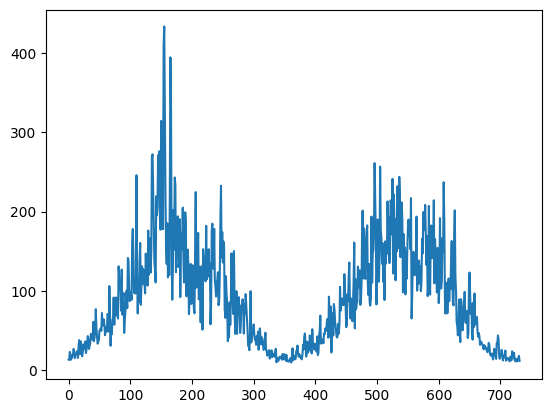

In [81]:
plt.plot(y_pred_real)

### Accuracy

In order to make a comparison of the models' performance, a systematic analysis of statistical evaluation metrics, including the R² score, Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE) is cumputed.

In [82]:
df_org=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df_org = df_org.rename(columns={'datetime': 'ds', 'solarradiation': 'y'})
test_org = df_org[df_org['ds'] >= '2022-12-31']

In [83]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['y'], y_pred_real))
mae = mean_absolute_error(test_org['y'], y_pred_real)
r2 = r2_score(test_org['y'], y_pred_real)
mape = mean_absolute_percentage_error(test_org['y'], y_pred_real)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"MAPE: {mape:4f}")

RMSE: 30.8953
MAE: 21.1415
R² Score: 0.8286
MAPE: 0.334457


In [177]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))


In [178]:
print("SMAPE:", smape(test_org['y'], y_pred_real))

SMAPE: 26.950996585321718


### Plot Actual vs Predicted

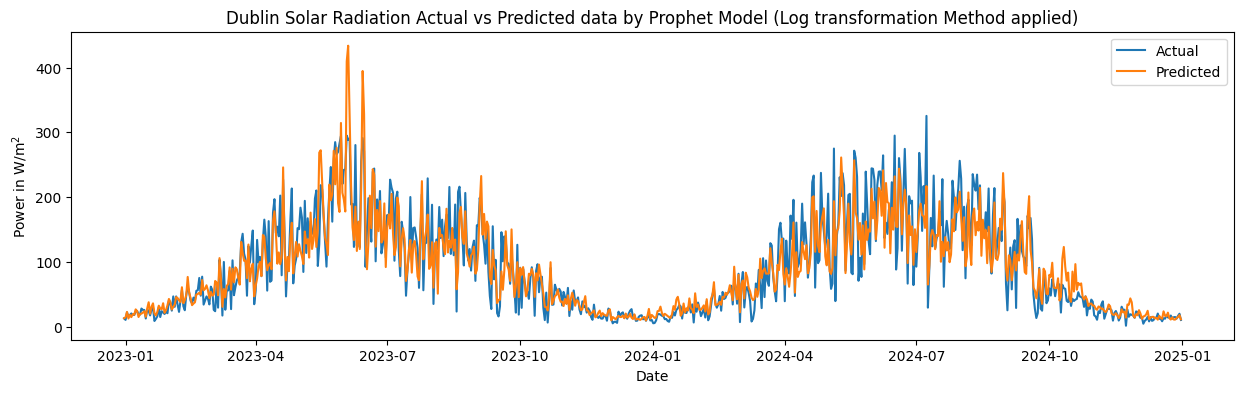

In [86]:
plt.figure(figsize=(15,4))
plt.plot(test_org['ds'],test_org['y'], label="Actual")
plt.plot(test_org['ds'],y_pred_real, label="Predicted")
plt.legend()
plt.title("Dublin Solar Radiation Actual vs Predicted data by Prophet Model (Log transformation Method applied)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

### Actual vs Predicted 60 days plot

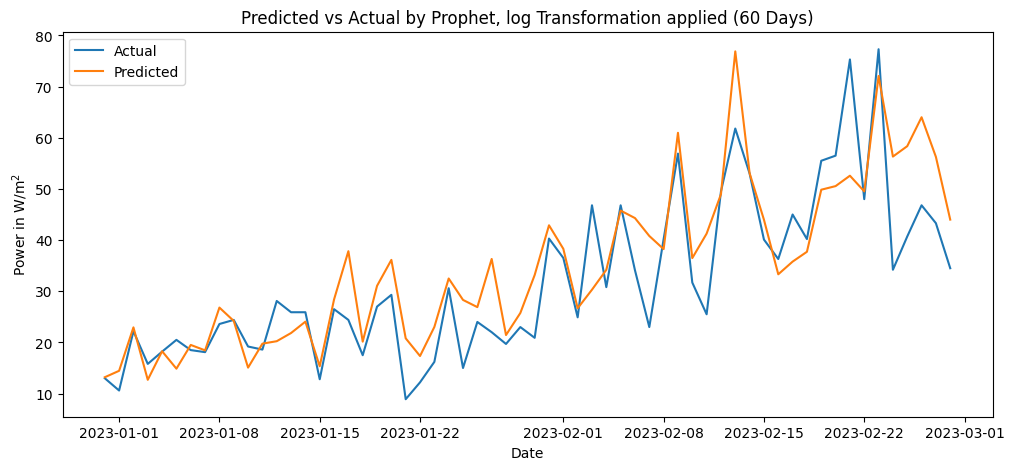

In [85]:
plt.figure(figsize=(12,5))
plt.plot(test_org['ds'][:60],test_org['y'][:60], label="Actual")
plt.plot(test_org['ds'][:60],y_pred_real[:60], label="Predicted")
plt.legend()
plt.title("Predicted vs Actual by Prophet, log Transformation applied (60 Days)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

In [53]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.set_index("datetime", inplace=True)
df = df.sort_index()

In [54]:
# last actual value before test starts
last_train_value = df.loc['2022-12-29', 'solarradiation']

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(predicted_best['yhat'])

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)

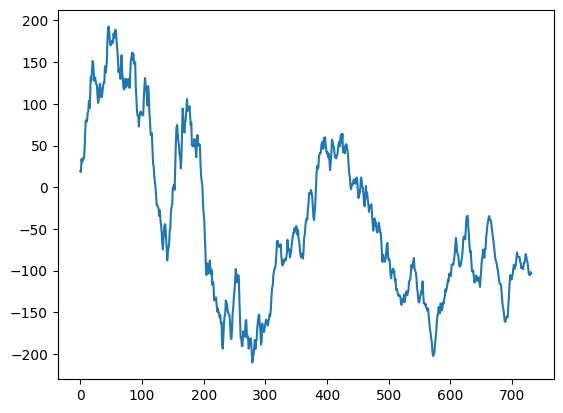

In [55]:
plt.plot(y_pred_original)

### Accuracy

# Experiment 4:
To develop a forecasting Model using Prophet utilising **Cross-validation** technique. 


### Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
##Plots
import matplotlib.pyplot as plt
import seaborn as sns

#Prophet model
from prophet import Prophet

# Accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#random seachcv
from sklearn.model_selection import RandomizedSearchCV
import random
#cross-validation
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric


## Load Dataset

In [2]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Prophet model's data processing

Prophet models require a column called 'ds' for time, and 'y' for the target feature


In [3]:
# Rename columns as Prophet expects
df = df.rename(columns={'datetime': 'ds', 'solarradiation': 'y'})


Adittionally, the exogenous variables have to be defined into a list

In [6]:
df.columns

Index(['ds', 'tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'y'],
      dtype='object')

In [4]:
# Define Exogenous data or regressors
X =['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility']

### Split data into 80/20

Creating the features for training and testing prophet model

In [5]:
# Separate historical and future data
train = df[df['ds'] < '2022-12-31']
test = df[df['ds'] >= '2022-12-31'].copy()

In [55]:
train.head()

,ds,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


## Building the Model

In [92]:
# Initialize Prophet model
model = Prophet(yearly_seasonality=True,
    weekly_seasonality=True,
    changepoint_prior_scale=0.1,       # allow more trend flexibility
    seasonality_prior_scale=20.0, )     # allow stronger seasonal variation)

In [93]:
# add regressors (exogenous variables)

for x in X:
    model.add_regressor(x, standardize='auto')

In [226]:
# checking for exogenous variables that the model expects
print("Model expects:", list(model.extra_regressors.keys()))


Model expects: ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility']


### Fit the model

In [94]:
# Fit the model using train data
model.fit(train)

20:34:01 - cmdstanpy - INFO - Chain [1] start processing
20:34:01 - cmdstanpy - INFO - Chain [1] done processing


### Cross-validation

Here to make a fair comparison against the other models, 5 folds will be calculated.

In [95]:
df_cv = cross_validation(
    model,
    initial='1460 days',   # train on first 4 years
    period='292 days',   # divide by 5
    horizon='5 days'   #forecast 5
)

  0%|          | 0/5 [00:00<?, ?it/s]

20:34:20 - cmdstanpy - INFO - Chain [1] start processing
20:34:20 - cmdstanpy - INFO - Chain [1] done processing
20:34:20 - cmdstanpy - INFO - Chain [1] start processing
20:34:20 - cmdstanpy - INFO - Chain [1] done processing
20:34:21 - cmdstanpy - INFO - Chain [1] start processing
20:34:21 - cmdstanpy - INFO - Chain [1] done processing
20:34:22 - cmdstanpy - INFO - Chain [1] start processing
20:34:22 - cmdstanpy - INFO - Chain [1] done processing
20:34:23 - cmdstanpy - INFO - Chain [1] start processing
20:34:23 - cmdstanpy - INFO - Chain [1] done processing


In [99]:
df_cv.shape

(25, 6)

In [100]:
df_perf = performance_metrics(df_cv)

In [101]:
df_perf

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,1 days,1193.786665,34.551218,25.505728,0.614188,0.311397,0.420389,0.8
1,2 days,642.798625,25.353474,20.374806,0.227985,0.218236,0.269428,0.8
2,3 days,752.171949,27.425753,25.236234,0.413988,0.210188,0.433427,1.0
3,4 days,81.797614,9.044203,7.105237,0.092827,0.057594,0.094720,1.0
4,5 days,345.903481,18.598481,15.822915,0.234258,0.162930,0.297150,1.0


### Mean of Statistical Evaluation Metrics

In [102]:
print(df_perf[['rmse', 'mae', 'mape']].mean())

rmse    22.994626
mae     18.808984
mape     0.316649
dtype: float64


In [106]:
r2 = r2_score(df_cv['y'], df_cv['yhat'])
print("R² Score:", r2)

R² Score: 0.8380400011576055


# Experiment 5:
To predict future. 30 days ahead.

### Load dataset

In [6]:
df = pd.read_csv("dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
df.tail()


,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
3648,2024-12-27,9.9,95.4,0.075,17.6,12.7,201.7,1030.8,90.8,9.5,15.0
3649,2024-12-28,9.1,90.2,0.002,31.7,17.8,232.8,1027.7,83.9,17.0,12.5
3650,2024-12-29,9.9,86.2,0.078,48.2,29.1,241.1,1026.8,77.1,16.4,16.8
3651,2024-12-30,10.0,81.4,0.001,55.1,29.9,230.7,1020.9,70.9,21.1,20.1
3652,2024-12-31,10.9,86.2,8.296,68.7,42.3,228.0,1008.0,87.5,13.5,10.5


### Select target and exogenous data


In [21]:
TARGET = 'solarradiation'
EXOG = ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
        'winddir', 'sealevelpressure', 'cloudcover', 'visibility']



### Prophet feature engineering

In [22]:
# Rename columns as Prophet expects
df = df.rename(columns={"datetime": "ds", TARGET: "y"})
df = df[['ds', 'y'] + EXOG]


### Building the Model with best parameters

In [25]:
model= Prophet(
    growth= 'linear',
    seasonality_mode= 'additive',
    yearly_seasonality= 16,
    weekly_seasonality= 0,
    daily_seasonality= 0, 
    changepoint_prior_scale= 0.003,
    changepoint_range= 0.85,
    n_changepoints= 30,
    seasonality_prior_scale= 0.5,
    holidays_prior_scale= 0.1,

                )

for x in EXOG:
    model.add_regressor(x, mode='additive', prior_scale=3, standardize='auto')



### Fit the model

In [26]:
model.fit(df)

15:32:01 - cmdstanpy - INFO - Chain [1] start processing
15:32:01 - cmdstanpy - INFO - Chain [1] done processing


### Seasonal averanges function

Multi-year climatology refers to the analysis of climate data averaged over multiple years for specific days of the year (doy). This approach helps identify patterns and trends in weather data.

In [27]:
def make_seasonal_data(df, exog_cols=EXOG):
    df = df.copy()
    df.index = pd.to_datetime(df['ds']) #index from ds
    df = df.sort_index()
    df['doy'] = df.index.dayofyear
    df['hour'] = 0  # daily data gives hour=0
    profiles = (
        df.groupby(['doy', 'hour'])[exog_cols] #creating day of day and hour, hour is o, we olnly have daily data
          .median() #median
          .reset_index()
    )
    return profiles


### Create a dataframe

in order to predict future values a structured future dataframe has to be created. Using the DoY median function it is possible to create exogenos data to make predictions.

In [12]:
def make_seasonal_future_data(df, start_date, periods, exog_cols=EXOG):
    df = df.copy()
    df.index = pd.to_datetime(df['ds'])
    df = df.sort_index()
    #computing DoY median function
    profiles = make_seasonal_data(df, exog_cols=exog_cols)
    profiles = profiles.set_index(['doy', 'hour']) #index by day-of-year and hour/time

    #create future daily index
    future_index = pd.date_range(start=start_date, periods=periods, freq='D')
    
    df_future = pd.DataFrame(index=future_index)
    df_future['doy'] = df_future.index.dayofyear
    df_future['hour'] = 0 #hour is zero, daily observations
   #append the syntetic exogenous data
    rows = []
    for i in df_future.index:
        key = (i.dayofyear, 0)
        if key in profiles.index:
            rows.append(profiles.loc[key, exog_cols].values)
       

    df_future_exog = pd.DataFrame(rows, index=future_index, columns=exog_cols)
    df_future_exog[TARGET] = np.nan #nan values to solar radiation
    return df_future_exog


### Create future data frame

In [14]:
future = make_seasonal_future_data(df, start_date='2025-01-01',periods=30,exog_cols=EXOG)

In [16]:
future.head()

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
2025-01-01,7.85,84.35,0.8515,60.85,29.70,231.05,1010.45,61.80,16.30,NaN
2025-01-02,8.50,84.05,0.3145,59.40,31.15,226.55,1011.90,52.35,17.30,NaN
2025-01-03,7.75,86.35,0.7220,52.35,29.45,251.30,1014.10,64.00,16.85,NaN
2025-01-04,6.95,86.35,0.0525,42.65,22.50,239.60,1017.70,68.10,17.80,NaN
2025-01-05,7.10,85.55,0.0155,41.20,23.95,214.50,1019.20,73.90,18.60,NaN


Prophet data engineering

In [17]:
future['ds']=future.index
future= future.rename(columns={"solarradiation": "y"})

In [18]:
future.head()

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,y,ds
2025-01-01,7.85,84.35,0.8515,60.85,29.70,231.05,1010.45,61.80,16.30,NaN,2025-01-01
2025-01-02,8.50,84.05,0.3145,59.40,31.15,226.55,1011.90,52.35,17.30,NaN,2025-01-02
2025-01-03,7.75,86.35,0.7220,52.35,29.45,251.30,1014.10,64.00,16.85,NaN,2025-01-03
2025-01-04,6.95,86.35,0.0525,42.65,22.50,239.60,1017.70,68.10,17.80,NaN,2025-01-04
2025-01-05,7.10,85.55,0.0155,41.20,23.95,214.50,1019.20,73.90,18.60,NaN,2025-01-05


### Predict solar radiation future

In [28]:
forecast = model.predict(future)

forecast = forecast[['ds', 'yhat']]


In [29]:
forecast

,ds,yhat
0,2025-01-01,15.366284
1,2025-01-02,30.333624
2,2025-01-03,15.201757
3,2025-01-04,11.935738
4,2025-01-05,12.160285
5,2025-01-06,20.994857
6,2025-01-07,14.880472
7,2025-01-08,31.098918
8,2025-01-09,16.541803
9,2025-01-10,23.739253


### Plot History + predicted data

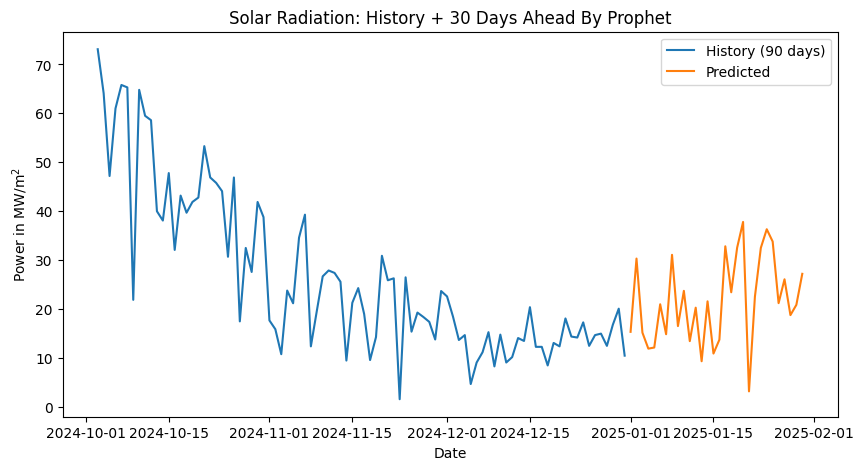

In [30]:
plt.figure(figsize=(10,5))
plt.plot(df['ds'][-90:], df['y'][-90:], label='History (90 days)')
plt.plot(forecast['ds'][-30:], forecast['yhat'][-30:], label='Predicted')
plt.title('Solar Radiation: History + 30 Days Ahead By Prophet')
plt.xlabel('Date')
plt.ylabel('Power in MW/m$^2$')
plt.legend()
plt.show()


In [512]:
forecast.to_csv('forecast_by_prophet.csv', index=True)